# Decision Tree Classification Laboratory Activity
## Online Shoppers Purchasing Intention

**Dataset file:** `online_shoppers_intention.csv`

This notebook follows the supplied laboratory instructions: define the classification problem, describe and preprocess the dataset, perform EDA, split the data 80/20, build a default Decision Tree, test additional parameter configurations, compare metrics, visualize the selected tree, and answer the reflection questions.

**Target variable:** `Revenue` (whether the online shopping session resulted in a purchase).

## 1. Establish the Classification Problem

**1. What problem do you want to solve?**  
Predict whether an online shopping session will result in a purchase.

**2. What is the dependent (target) variable?**  
`Revenue`, a Boolean variable indicating whether the session resulted in revenue (`True`) or not (`False`).

**3. What are the independent (input) variables?**  
The other 17 columns, including page counts and durations, bounce and exit rates, page values, month, operating system, browser, region, traffic type, visitor type, weekend status, and other session-related information.

**4. Why is this suitable for Decision Tree classification?**  
The target has two classes, and the dataset contains a mix of numerical and categorical features. A Decision Tree can model non-linear relationships and produce interpretable decision rules.

## 2. Collect and Describe the Dataset

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report
)

pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid")

file_path = "c:/Users/Alexa/AppData/Local/Temp/06406e63-5e10-4d65-b5bf-97af50687558_archive.zip.558/online_shoppers_intention.csv"
df = pd.read_csv(file_path)

print("Dataset name: Online Shoppers Purchasing Intention")
print("Dataset shape:", df.shape)
print("Number of records:", df.shape[0])
print("Number of input features:", df.shape[1] - 1)
print("Target variable: Revenue")
print("\nColumns:")
print(df.columns.tolist())

if "Revenue" not in df.columns:
    raise ValueError("Expected target column 'Revenue' was not found.")

print("\nTarget class counts:")
display(df["Revenue"].value_counts(dropna=False).rename_axis("Revenue").to_frame("Count"))

print("\nTarget class percentages:")
display((df["Revenue"].value_counts(normalize=True, dropna=False) * 100)
        .round(2).rename_axis("Revenue").to_frame("Percentage"))

print("\nFirst five rows:")
display(df.head())

Dataset name: Online Shoppers Purchasing Intention
Dataset shape: (12330, 18)
Number of records: 12330
Number of input features: 17
Target variable: Revenue

Columns:
['Administrative', 'Administrative_Duration', 'Informational', 'Informational_Duration', 'ProductRelated', 'ProductRelated_Duration', 'BounceRates', 'ExitRates', 'PageValues', 'SpecialDay', 'Month', 'OperatingSystems', 'Browser', 'Region', 'TrafficType', 'VisitorType', 'Weekend', 'Revenue']

Target class counts:


,Count
Revenue,
False,10422
True,1908



Target class percentages:


,Percentage
Revenue,
False,84.53
True,15.47



First five rows:


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
0,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,1,1,1,1,Returning_Visitor,False,False
1,0,0.0,0,0.0,2,64.000000,0.00,0.10,0.0,0.0,Feb,2,2,1,2,Returning_Visitor,False,False
2,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,4,1,9,3,Returning_Visitor,False,False
3,0,0.0,0,0.0,2,2.666667,0.05,0.14,0.0,0.0,Feb,3,2,2,4,Returning_Visitor,False,False
4,0,0.0,0,0.0,10,627.500000,0.02,0.05,0.0,0.0,Feb,3,3,1,4,Returning_Visitor,True,False


### Dataset description

Each row represents an online shopping session. The target `Revenue` indicates whether that session ended in a purchase. The supplied file is expected to have more than the required 1,000 records.

**Source:** The `online_shoppers_intention.csv` file supplied with this activity. If your instructor requires a public-source URL, add the exact URL from where you obtained the dataset.

## 3. Preprocess the Data and Perform EDA

In [4]:
print("Data types:")
display(df.dtypes.rename("Data Type").to_frame())

print("\nMissing values per column:")
display(df.isna().sum().rename("Missing Count").to_frame())

print("\nExact duplicate rows:", df.duplicated().sum())

# Make a copy so the original loaded data remains unchanged.
data = df.copy()

# Remove exact duplicate rows if present.
data = data.drop_duplicates().copy()

# Remove rows with a missing target because supervised learning requires a known label.
data = data.dropna(subset=["Revenue"]).copy()

# Separate target and features.
X = data.drop(columns=["Revenue"])
y = data["Revenue"].astype(bool)

print("Shape after basic cleaning:", data.shape)
print("\nTarget balance after cleaning:")
display(y.value_counts().rename_axis("Revenue").to_frame("Count"))

Data types:


,Data Type
Administrative,int64
Administrative_Duration,float64
Informational,int64
Informational_Duration,float64
ProductRelated,int64
ProductRelated_Duration,float64
BounceRates,float64
ExitRates,float64
PageValues,float64
SpecialDay,float64



Missing values per column:


,Missing Count
Administrative,0
Administrative_Duration,0
Informational,0
Informational_Duration,0
ProductRelated,0
ProductRelated_Duration,0
BounceRates,0
ExitRates,0
PageValues,0
SpecialDay,0



Exact duplicate rows: 125
Shape after basic cleaning: (12205, 18)

Target balance after cleaning:


,Count
Revenue,
False,10297
True,1908


### Preprocessing explanation

- **Missing values:** Check every column. Missing target labels are removed because the model cannot learn a known class from them. The next cell imputes missing input values.
- **Duplicates:** Exact duplicate rows are removed to reduce repeated identical records.
- **Categorical variables:** Text categories are one-hot encoded. This allows scikit-learn's Decision Tree to use categories such as `Month` and `VisitorType`.
- **Numerical variables:** Kept on their original scales. Decision Trees generally do not require feature scaling.
- **Train-test split:** The same stratified 80/20 split and random state are reused for every model so results can be compared fairly.

Numeric features: ['Administrative', 'Administrative_Duration', 'Informational', 'Informational_Duration', 'ProductRelated', 'ProductRelated_Duration', 'BounceRates', 'ExitRates', 'PageValues', 'SpecialDay', 'OperatingSystems', 'Browser', 'Region', 'TrafficType']
Categorical features: ['Month', 'VisitorType', 'Weekend']


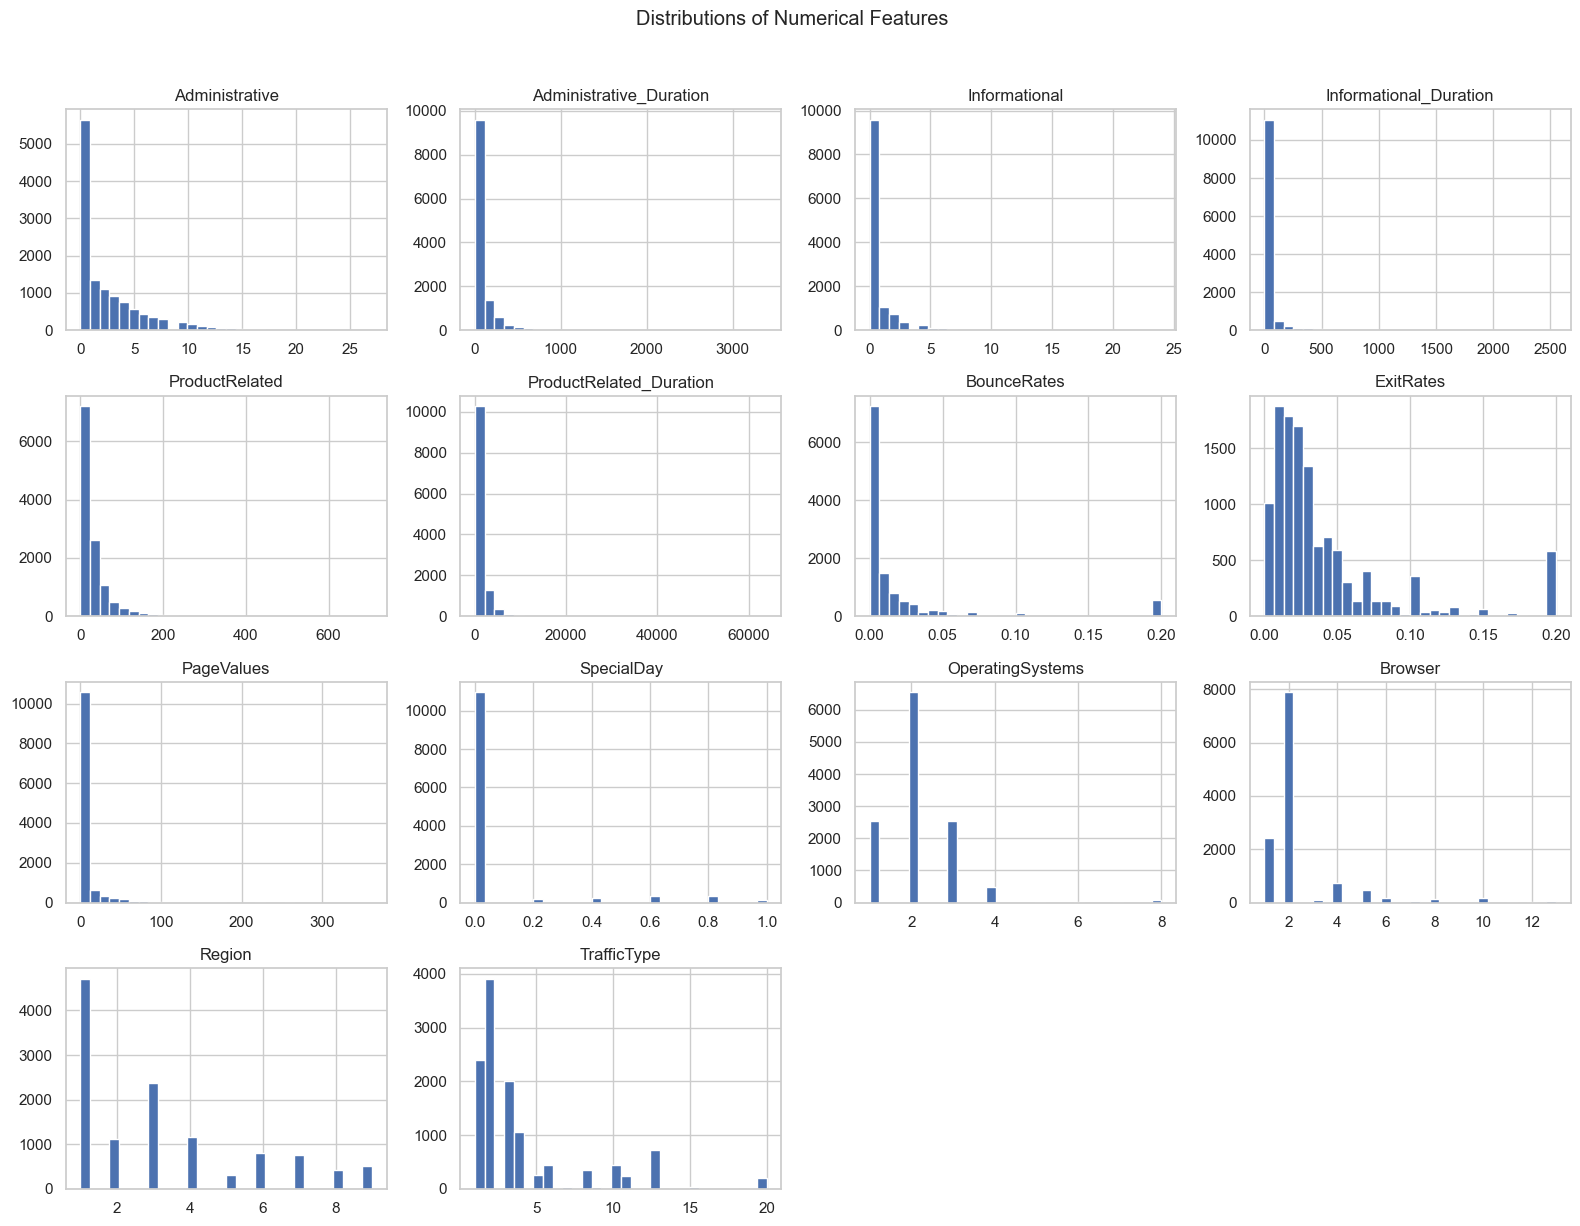

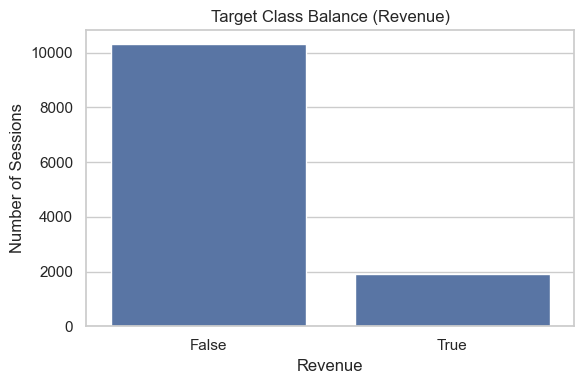

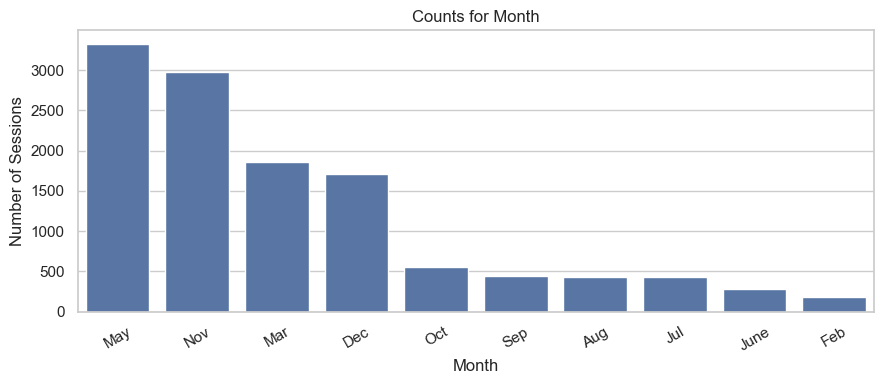

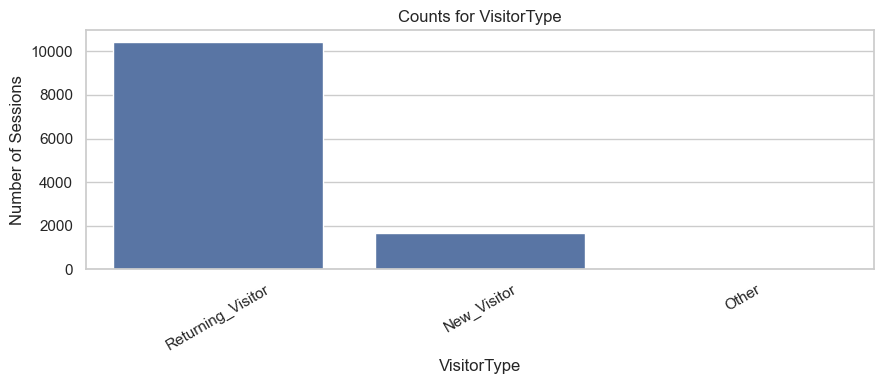

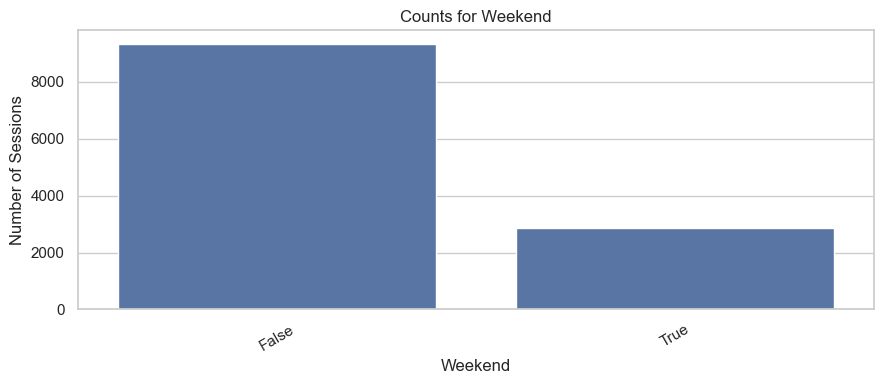

In [5]:
# Identify numeric and categorical feature columns.
numeric_features = X.select_dtypes(include=["number"]).columns.tolist()
categorical_features = X.select_dtypes(exclude=["number"]).columns.tolist()

print("Numeric features:", numeric_features)
print("Categorical features:", categorical_features)

# Simple EDA: numerical distributions.
X[numeric_features].hist(figsize=(16, 12), bins=30)
plt.suptitle("Distributions of Numerical Features", y=1.02)
plt.tight_layout()
plt.show()

# Class balance plot.
plt.figure(figsize=(6, 4))
sns.countplot(x=y.astype(str))
plt.title("Target Class Balance (Revenue)")
plt.xlabel("Revenue")
plt.ylabel("Number of Sessions")
plt.tight_layout()
plt.show()

# Explore selected categorical feature counts if present.
for col in ["Month", "VisitorType", "Weekend"]:
    if col in X.columns:
        plt.figure(figsize=(9, 4))
        sns.countplot(data=data, x=col, order=data[col].value_counts().index)
        plt.title(f"Counts for {col}")
        plt.xlabel(col)
        plt.ylabel("Number of Sessions")
        plt.xticks(rotation=30)
        plt.tight_layout()
        plt.show()

### EDA interpretation, insight, and recommended action

**Interpretation:** The target-count table and charts show whether purchase and non-purchase sessions are evenly represented. Numerical histograms reveal the shapes and ranges of the input variables, while category plots show the most common session categories.

**Insight:** If the `Revenue=False` class is much larger than `Revenue=True`, accuracy alone may hide weak purchase detection. Class-specific precision, recall, and F1-score should therefore also be checked.

**Recommended action:** Keep the class distribution in mind when evaluating the model. Use a stratified split and inspect the classification report, especially the metrics for the purchase class.

## 4. Split the Data (80% Training, 20% Testing)

In [6]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))
print("Training fraction:", round(len(X_train) / len(data), 3))
print("Testing fraction:", round(len(X_test) / len(data), 3))

# Preprocessing is fitted only on the training data through each Pipeline.
def make_preprocessor():
    try:
        encoder = OneHotEncoder(handle_unknown="ignore", sparse_output=False)
    except TypeError:  # Compatibility with older scikit-learn versions
        encoder = OneHotEncoder(handle_unknown="ignore", sparse=False)

    return ColumnTransformer(
        transformers=[
            ("numeric", "passthrough", numeric_features),
            ("categorical", encoder, categorical_features)
        ],
        remainder="drop"
    )

Training records: 9764
Testing records: 2441
Training fraction: 0.8
Testing fraction: 0.2


## 5. Build a Baseline Decision Tree Model

In [7]:
baseline = Pipeline([
    ("preprocessor", make_preprocessor()),
    ("model", DecisionTreeClassifier(random_state=42))
])

baseline.fit(X_train, y_train)
baseline_train_pred = baseline.predict(X_train)
baseline_test_pred = baseline.predict(X_test)

print(f"Baseline training accuracy: {accuracy_score(y_train, baseline_train_pred):.4f}")
print(f"Baseline testing accuracy:  {accuracy_score(y_test, baseline_test_pred):.4f}")

Baseline training accuracy: 1.0000
Baseline testing accuracy:  0.8632


### Baseline interpretation

The baseline uses the default Decision Tree parameters. Compare training and testing accuracy: a much higher training score than testing score can indicate overfitting, where the tree memorizes training patterns that do not generalize as well to unseen sessions.

**Recommended action:** Do not choose the final model based only on training accuracy. Evaluate test precision, recall, F1-score, and tree complexity as well.

## 6. Experiment with Decision Tree Parameters

In [8]:
# The baseline plus at least three additional configurations.
# The first trials vary one parameter at a time; later trials combine settings.
configurations = [
    ("Baseline", {}),
    ("Trial 1 - shallow tree", {"max_depth": 3}),
    ("Trial 2 - depth 5", {"max_depth": 5}),
    ("Trial 3 - depth 10", {"max_depth": 10}),
    ("Trial 4 - entropy", {"criterion": "entropy"}),
    ("Trial 5 - min split 10", {"min_samples_split": 10}),
    ("Trial 6 - min leaf 5", {"min_samples_leaf": 5}),
    ("Trial 7 - combined regularized", {
        "criterion": "entropy",
        "max_depth": 10,
        "min_samples_split": 10,
        "min_samples_leaf": 5
    })
]

models = {}
rows = []

for name, params in configurations:
    pipe = Pipeline([
        ("preprocessor", make_preprocessor()),
        ("model", DecisionTreeClassifier(random_state=42, **params))
    ])
    pipe.fit(X_train, y_train)

    train_pred = pipe.predict(X_train)
    test_pred = pipe.predict(X_test)
    tree = pipe.named_steps["model"]

    rows.append({
        "Trial": name,
        "Criterion": params.get("criterion", "gini (default)"),
        "Max Depth": params.get("max_depth", "None (default)"),
        "Min Samples Split": params.get("min_samples_split", 2),
        "Min Samples Leaf": params.get("min_samples_leaf", 1),
        "Train Accuracy": accuracy_score(y_train, train_pred),
        "Test Accuracy": accuracy_score(y_test, test_pred),
        "Precision (purchase)": precision_score(y_test, test_pred, pos_label=True, zero_division=0),
        "Recall (purchase)": recall_score(y_test, test_pred, pos_label=True, zero_division=0),
        "F1-score (purchase)": f1_score(y_test, test_pred, pos_label=True, zero_division=0),
        "Depth": tree.get_depth(),
        "Leaves": tree.get_n_leaves()
    })
    models[name] = pipe

results = pd.DataFrame(rows)
display(results.round(4))

,Trial,Criterion,Max Depth,Min Samples Split,Min Samples Leaf,Train Accuracy,Test Accuracy,Precision (purchase),Recall (purchase),F1-score (purchase),Depth,Leaves
0,Baseline,gini (default),None (default),2,1,1.0000,0.8632,0.5609,0.5785,0.5696,22,783
1,Trial 1 - shallow tree,gini (default),3,2,1,0.8975,0.8992,0.6954,0.6335,0.6630,3,8
2,Trial 2 - depth 5,gini (default),5,2,1,0.9099,0.9025,0.7069,0.6440,0.6740,5,32
3,Trial 3 - depth 10,gini (default),10,2,1,0.9517,0.8865,0.6431,0.6178,0.6302,10,307
4,Trial 4 - entropy,entropy,None (default),2,1,1.0000,0.8624,0.5596,0.5654,0.5625,26,770
5,Trial 5 - min split 10,gini (default),None (default),10,1,0.9684,0.8710,0.5898,0.5759,0.5828,21,536
6,Trial 6 - min leaf 5,gini (default),None (default),2,5,0.9506,0.8730,0.5963,0.5838,0.5899,20,468
7,Trial 7 - combined regularized,entropy,10,10,5,0.9362,0.8890,0.6667,0.5812,0.6210,10,239


### Experimentation interpretation

- A **shallow tree** is simpler and may underfit if it cannot capture useful patterns.
- A **deeper tree** can learn more detailed patterns, but a large gap between training and test accuracy can indicate overfitting.
- Increasing `min_samples_split` or `min_samples_leaf` usually restricts the tree from making very small, highly specific splits.
- `gini` and `entropy` are alternative split criteria. They may produce similar or different trees; use the table rather than assuming one is always better.

**Decision rule:** Select a model with good test performance and reasonable complexity. Consider purchase-class F1-score and recall alongside accuracy.

## 7. Evaluate and Compare the Models

In [9]:
for name, model in models.items():
    pred = model.predict(X_test)
    print("=" * 80)
    print(name)
    print(f"Train accuracy: {accuracy_score(y_train, model.predict(X_train)):.4f}")
    print(f"Test accuracy:  {accuracy_score(y_test, pred):.4f}")
    print("\nConfusion matrix (rows = actual, columns = predicted; order False, True):")
    print(confusion_matrix(y_test, pred, labels=[False, True]))
    print("\nClassification report:")
    print(classification_report(
        y_test, pred,
        labels=[False, True],
        target_names=["No Purchase (False)", "Purchase (True)"],
        zero_division=0
    ))

Baseline
Train accuracy: 1.0000
Test accuracy:  0.8632

Confusion matrix (rows = actual, columns = predicted; order False, True):
[[1886  173]
 [ 161  221]]

Classification report:
                     precision    recall  f1-score   support

No Purchase (False)       0.92      0.92      0.92      2059
    Purchase (True)       0.56      0.58      0.57       382

           accuracy                           0.86      2441
          macro avg       0.74      0.75      0.74      2441
       weighted avg       0.86      0.86      0.86      2441

Trial 1 - shallow tree
Train accuracy: 0.8975
Test accuracy:  0.8992

Confusion matrix (rows = actual, columns = predicted; order False, True):
[[1953  106]
 [ 140  242]]

Classification report:
                     precision    recall  f1-score   support

No Purchase (False)       0.93      0.95      0.94      2059
    Purchase (True)       0.70      0.63      0.66       382

           accuracy                           0.90      2441
         

In [10]:
# Select the model with the highest purchase-class F1-score.
# If scores tie, prefer the shallower tree, then fewer leaves.
results_for_choice = results.copy()
results_for_choice["Depth_numeric"] = pd.to_numeric(results_for_choice["Depth"])
results_for_choice = results_for_choice.sort_values(
    by=["F1-score (purchase)", "Test Accuracy", "Depth_numeric", "Leaves"],
    ascending=[False, False, True, True]
)

selected_name = results_for_choice.iloc[0]["Trial"]
selected_model = models[selected_name]

print("Selected model:", selected_name)
print(results_for_choice.head(5).drop(columns=["Depth_numeric"]).round(4).to_string(index=False))

train_acc = accuracy_score(y_train, selected_model.predict(X_train))
test_acc = accuracy_score(y_test, selected_model.predict(X_test))
print(f"\nSelected model training accuracy: {train_acc:.4f}")
print(f"Selected model testing accuracy:  {test_acc:.4f}")
if train_acc - test_acc > 0.10:
    print("Interpretation: The training-test gap is large, suggesting possible overfitting.")
elif train_acc < 0.75 and test_acc < 0.75:
    print("Interpretation: Both accuracies are relatively low, suggesting possible underfitting.")
else:
    print("Interpretation: Review the train-test gap together with F1-score and tree complexity to judge generalization.")

Selected model: Trial 2 - depth 5
                         Trial      Criterion      Max Depth  Min Samples Split  Min Samples Leaf  Train Accuracy  Test Accuracy  Precision (purchase)  Recall (purchase)  F1-score (purchase)  Depth  Leaves
             Trial 2 - depth 5 gini (default)              5                  2                 1          0.9099         0.9025                0.7069             0.6440               0.6740      5      32
        Trial 1 - shallow tree gini (default)              3                  2                 1          0.8975         0.8992                0.6954             0.6335               0.6630      3       8
            Trial 3 - depth 10 gini (default)             10                  2                 1          0.9517         0.8865                0.6431             0.6178               0.6302     10     307
Trial 7 - combined regularized        entropy             10                 10                 5          0.9362         0.8890              

### Comparison and interpretation

The printed metrics allow the models to be compared using accuracy, precision, recall, and F1-score. The confusion matrix shows correct and incorrect predictions for both classes.

- **True negatives:** non-purchase sessions correctly predicted as non-purchase.
- **False positives:** non-purchase sessions incorrectly predicted as purchases.
- **False negatives:** purchase sessions incorrectly predicted as non-purchases.
- **True positives:** purchase sessions correctly predicted as purchases.

A model may predict the majority non-purchase class well but miss purchase sessions. Check the purchase-class recall and F1-score before deciding whether the model is useful for business decisions.

## 8. Visualize and Interpret the Decision Tree

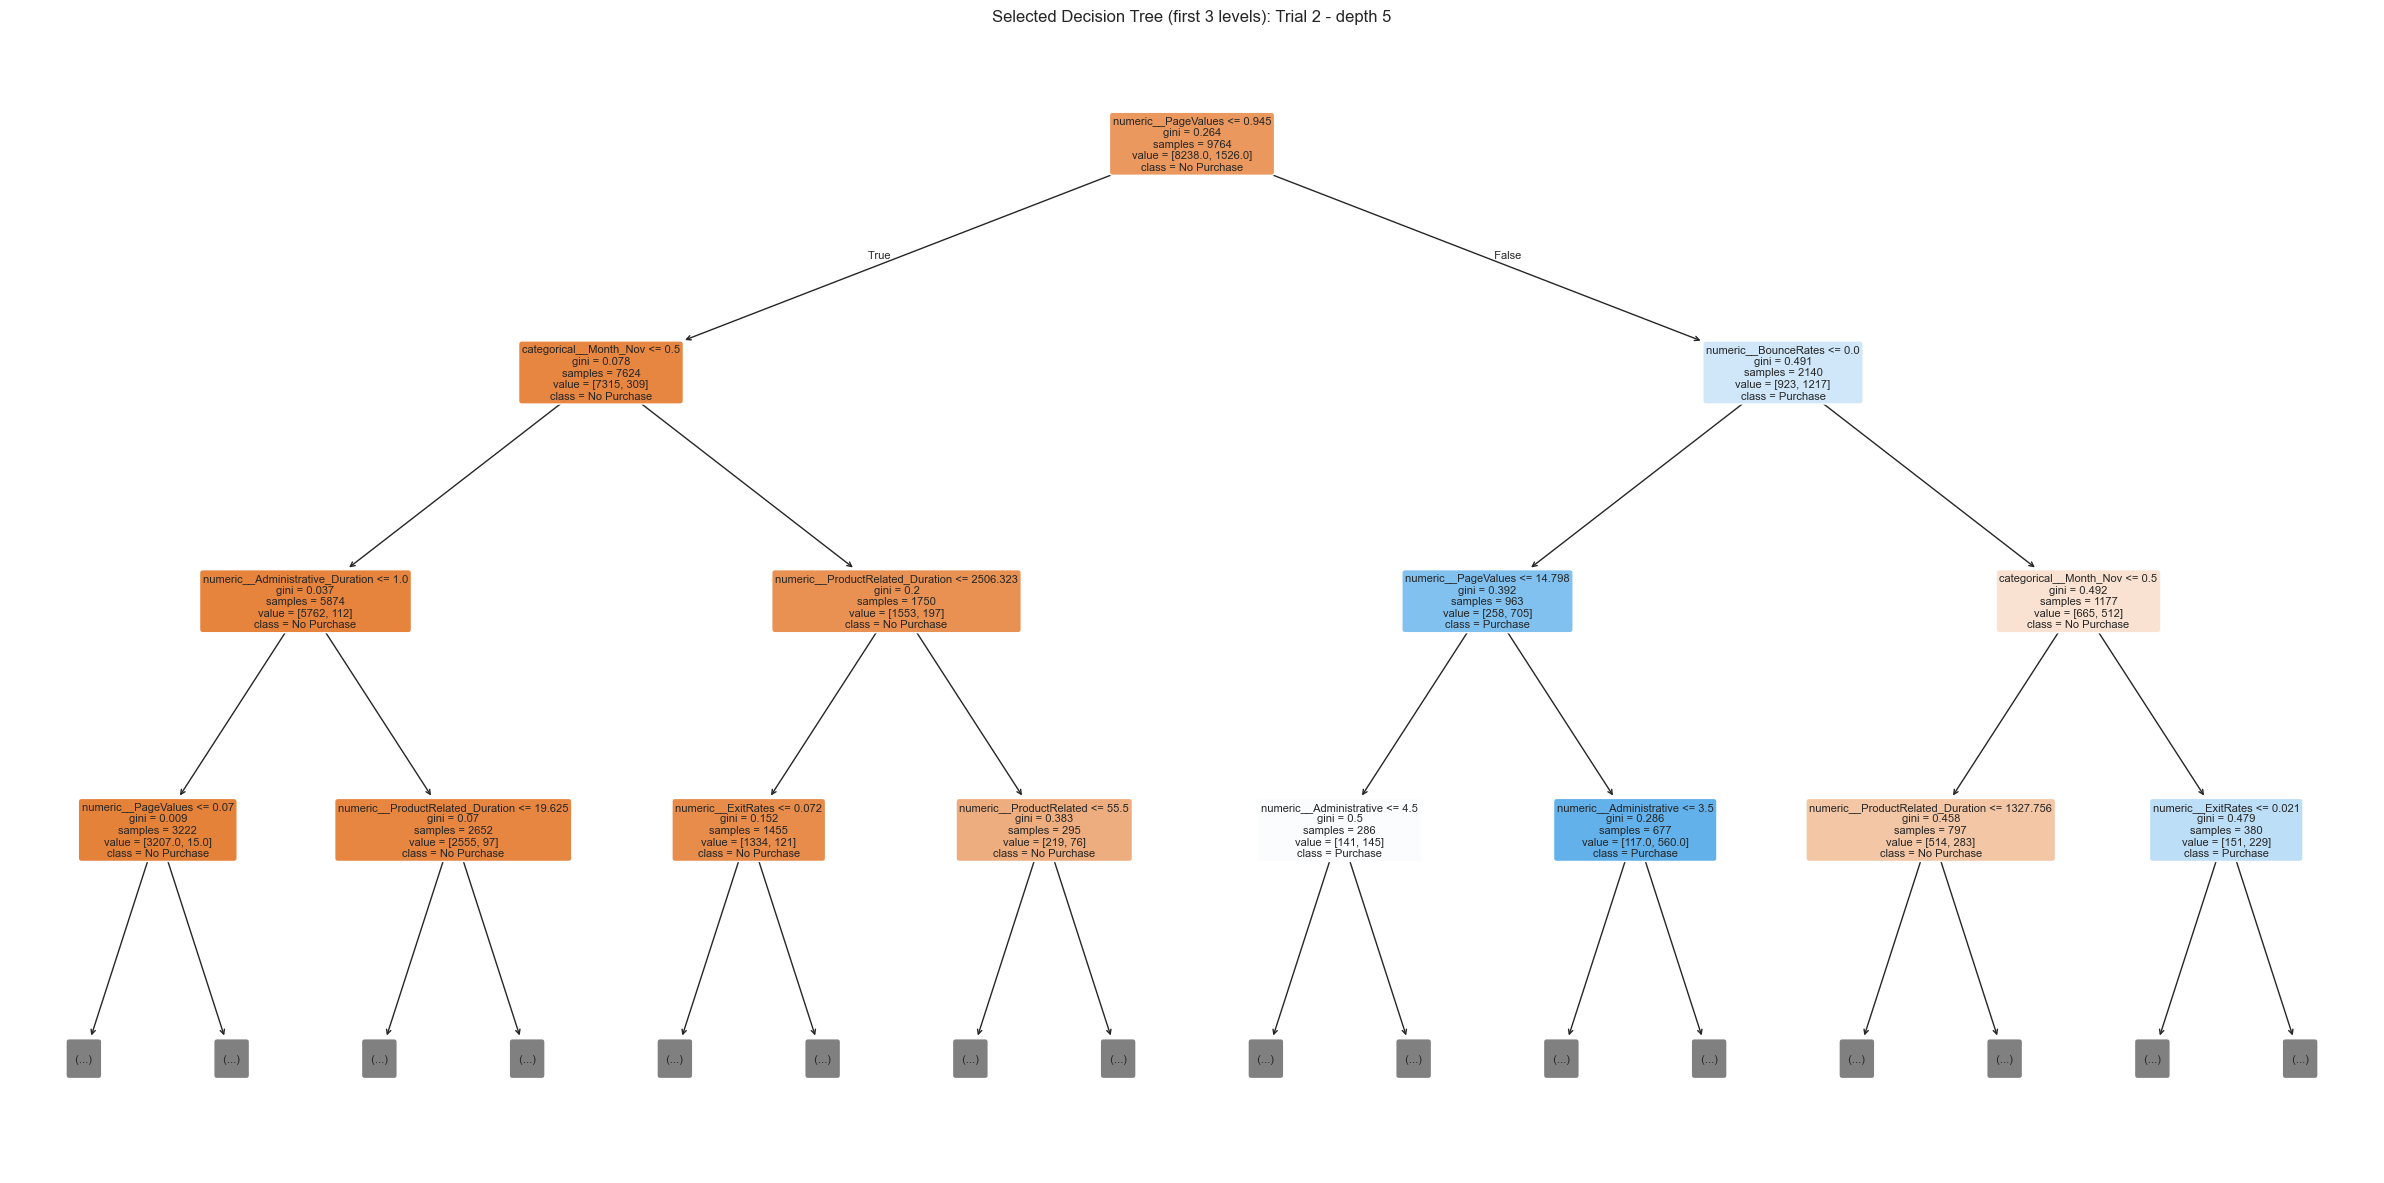

Selected tree full depth: 5
Selected tree leaves: 32


In [11]:
# Show only the first few levels so the figure remains readable.
selected_tree = selected_model.named_steps["model"]
feature_names = selected_model.named_steps["preprocessor"].get_feature_names_out()

plt.figure(figsize=(24, 12))
plot_tree(
    selected_tree,
    feature_names=feature_names,
    class_names=["No Purchase", "Purchase"],
    filled=True,
    rounded=True,
    max_depth=3,
    fontsize=8
)
plt.title(f"Selected Decision Tree (first 3 levels): {selected_name}")
plt.tight_layout()
plt.show()

print("Selected tree full depth:", selected_tree.get_depth())
print("Selected tree leaves:", selected_tree.get_n_leaves())

|--- numeric__PageValues <= 0.94
|   |--- categorical__Month_Nov <= 0.50
|   |   |--- numeric__Administrative_Duration <= 1.00
|   |   |   |--- numeric__PageValues <= 0.07
|   |   |   |   |--- truncated branch of depth 2
|   |   |   |--- numeric__PageValues >  0.07
|   |   |   |   |--- truncated branch of depth 2
|   |   |--- numeric__Administrative_Duration >  1.00
|   |   |   |--- numeric__ProductRelated_Duration <= 19.62
|   |   |   |   |--- truncated branch of depth 2
|   |   |   |--- numeric__ProductRelated_Duration >  19.62
|   |   |   |   |--- truncated branch of depth 2
|   |--- categorical__Month_Nov >  0.50
|   |   |--- numeric__ProductRelated_Duration <= 2506.32
|   |   |   |--- numeric__ExitRates <= 0.07
|   |   |   |   |--- truncated branch of depth 2
|   |   |   |--- numeric__ExitRates >  0.07
|   |   |   |   |--- truncated branch of depth 2
|   |   |--- numeric__ProductRelated_Duration >  2506.32
|   |   |   |--- numeric__ProductRelated <= 55.50
|   |   |   |   |--- trun

,Feature,Importance
8,numeric__PageValues,0.7740
6,numeric__BounceRates,0.0736
21,categorical__Month_Nov,0.0462
5,numeric__ProductRelated_Duration,0.0462
0,numeric__Administrative,0.0217
7,numeric__ExitRates,0.0143
1,numeric__Administrative_Duration,0.0080
19,categorical__Month_Mar,0.0055
3,numeric__Informational_Duration,0.0028
4,numeric__ProductRelated,0.0026


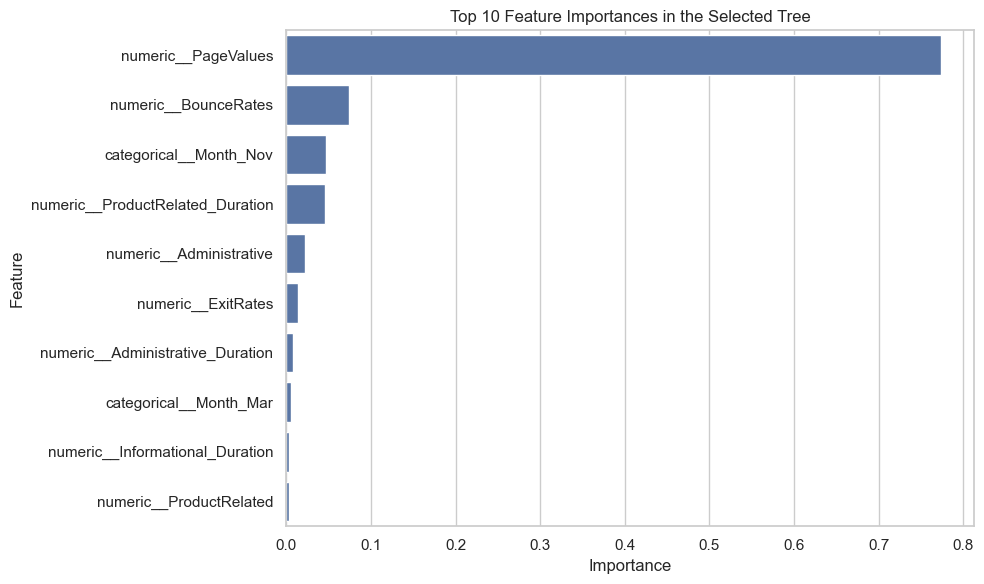

In [12]:
# Display the first rules of the selected tree.
rules_text = export_text(
    selected_tree,
    feature_names=list(feature_names),
    max_depth=3
)
print(rules_text)

# Top features by impurity-based importance.
importance = pd.DataFrame({
    "Feature": feature_names,
    "Importance": selected_tree.feature_importances_
}).sort_values("Importance", ascending=False)

print("\nTop 10 feature importances:")
display(importance.head(10).round(4))

plt.figure(figsize=(10, 6))
sns.barplot(data=importance.head(10), x="Importance", y="Feature")
plt.title("Top 10 Feature Importances in the Selected Tree")
plt.tight_layout()
plt.show()

## 9. Reflection Questions

### 1. How does a Decision Tree decide where to split the data?
A Decision Tree tests feature-based splits and selects a split that improves class separation according to its criterion, such as Gini impurity or entropy. It repeats this process on child nodes until a stopping rule is reached.

### 2. What happened to model performance when `max_depth` was increased or decreased?
Use the experiment table to describe the observed change. A shallow tree is simpler and may underfit. A deeper tree can improve training accuracy, but may overfit if test performance does not improve or the train-test gap grows.

### 3. How did changing `min_samples_split` or `min_samples_leaf` affect complexity and generalization?
Higher values restrict small splits or leaves, usually reducing tree complexity. This can reduce overfitting, although values that are too high may cause underfitting. Refer to the depth, leaves, and test metrics in the results table.

### 4. Did Gini and entropy produce the same tree and performance?
Compare the Baseline row with **Trial 4 - entropy**. The criteria may select different splits, but they can also produce similar results. State the actual accuracy, F1-score, depth, and leaf counts from your run.

### 5. Which configuration provided the best balance between training performance, testing performance, and tree complexity?
The notebook selects a candidate using purchase-class F1-score, then test accuracy, then shallower depth and fewer leaves as tie-breakers. Use the displayed selected model and comparison table to justify the final choice. If your instructor prefers a different metric, explain that choice.

### 6. What are the advantages and limitations of Decision Trees for this dataset?
**Advantages:** They can model non-linear relationships, handle mixed patterns after categorical encoding, require no feature scaling, and provide readable decision rules.

**Limitations:** Deep trees can overfit, small changes in data can change the learned tree, and a single tree may not perform as well as ensemble methods. The class imbalance can also make accuracy misleading, so purchase-class precision, recall, and F1-score should be considered.